# H100 음악 분류기 단순화 실험 결과

실험과 결과 검증을 완료했습니다. H100은 stopped, 계정 과금 속도는 0입니다.

| 구조 | 파라미터 | 평균 Music EER ↓ | 평균 File EER ↓ | 파일·음악 가중 부분합 ↑ |
|---|---:|---:|---:|---:|
| 기존 6층 + gated attention/max | 414,017 | 0.4333 | 0.3280 | 0.4554 |
| 단순화 2층 + max | 199,169 | 0.3731 | 0.3226 | 0.4741 |
| 동일 분할 Linear, seed 41 | 769 | 0.3667 | 0.3519 | 0.4626 |

Conv1D 결과는 seed 41·42·43 평균입니다. 단순화 후 Music EER은 6.02%p,
File EER은 0.53%p 낮아졌습니다. 파일·음악 가중 부분합은 전체 공식 점수가 아닙니다.
기존 공개 평가 자료를 재사용했으며, 평가 결과로 좋은 seed만 고르지 않았습니다.

Music EER의 seed 표준편차는 0.0386→0.0328로 줄었지만 File EER은 0.0086→0.0217로 늘었습니다.
단순화 모델의 최선 epoch는 3·6·9였으며 학습 후반의 튜닝 손실 상승은 남았습니다.
평균 튜닝 EER은 0.3082→0.3006으로 낮아졌지만 평균 튜닝 BCE는 0.5577→0.5691로 높아졌습니다.
이 결과만으로 과적합이 해결됐거나 모든 지표가 안정적으로 개선됐다고 볼 수는 없습니다.

기존 입력·분할·crop 70%·batch 128·학습 설정을 유지했습니다.
기존 모델의 세 seed 학습 곡선과 평가 예측은 이전 H100 기록을 오차 1e-6 이내로 재현했습니다.

성공한 노트북의 코드 셀 실행 구간은 100.2초입니다.
시작 잔액 11.555556→종료 잔액 11.095577, 계정 차감은 0.459979크레딧입니다.
차감액에는 첫 시도, 원인 확인, 재실행, 다운로드와 정지 전 대기가 포함됩니다.
첫 시도는 기존 분기의 연산 순서 변경으로 재현성 검증에 실패했고, 순서를 복원한 뒤 재실행했습니다.


## 1. 환경과 입력 확인

In [1]:
from pathlib import Path
import json, os, sys, time
import numpy as np
import torch
from IPython.display import display, Markdown
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from v6_data import sha256, write_json
from temporal_experiment import split_experiment, load_features, training_masks, evaluate_locked_test
from temporal_augmentation_experiment import run_augmentation_search
BATCH_SIZE = 128
OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)
PROJECT = Path('/root/V6_L40S'); FINAL = Path('/root/C3_Final')
DEADLINE = float(os.environ['V7_RESUMED_EPOCH']) + 30 * 60
manifest = json.loads((ROOT / 'input_manifest.json').read_text())
for name, digest in manifest['sha256'].items():
    assert sha256(ROOT / name) == digest, name
assert torch.cuda.is_available() and time.time() < DEADLINE
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True)
write_json(OUT / 'environment.json', dict(gpu=torch.cuda.get_device_name(), torch=torch.__version__,
    python=sys.version, deadline=DEADLINE, batch_size=BATCH_SIZE, deterministic_algorithms=True))
print({'GPU': torch.cuda.get_device_name(), 'torch': torch.__version__, 'compute_minutes': 30})

{'GPU': 'NVIDIA H100 80GB HBM3', 'torch': '2.9.1+cu130', 'compute_minutes': 30}


## 2. 분할과 캐시 검증
기존 C3 정제 정책을 유지합니다. PCM 중복과 유효 구간 없는 자료를 제외하고, 학습 자료에만 활성 프레임 비율 20% 기준 마스크를 적용합니다. 평가 자료에는 학습용 마스크를 적용하지 않습니다.

In [2]:
PLAN = json.loads((ROOT / 'full_data_plan.json').read_text())
BASELINE = json.loads((ROOT / 'baseline_predictions.json').read_text())
SPLIT = json.loads((ROOT / 'locked_split.json').read_text())
from v6_data import assert_disjoint
for a,b in [('train','tune'),('train','test'),('tune','test')]:
    assert_disjoint(SPLIT[a], SPLIT[b])
write_json(OUT / 'split.json', SPLIT)
records = load_features(SPLIT['train'] + SPLIT['tune'] + SPLIT['test'], PROJECT, FINAL)
masked = training_masks(SPLIT['train'], records, PLAN['quality'])
write_json(OUT / 'input_verification.json', dict(files=len(records), input_sha256=manifest['sha256'],
    split_sha256=sha256(OUT / 'split.json'), quality_policy=PLAN['policy'],
    baseline_sha256=sha256(ROOT / 'baseline_predictions.json'),
    cache_validation='Source audio SHA256 checked by CPU exporter; exact cache SHA256 and original identity checked on H100'))
from collections import Counter
for name, rows in SPLIT.items():
    print(name, len(rows), dict(Counter(r['source'].split('/')[0] for r in rows)))
import hashlib
def feature_hash(mapping):
    digest=hashlib.sha256()
    for key in sorted(mapping):
        digest.update(key.encode())
        for field in ('music','music_audible','starts'):
            digest.update(np.ascontiguousarray(mapping[key][field]).tobytes())
    return digest.hexdigest()
CACHE_BEFORE=(feature_hash(records),feature_hash(masked))


train 1008 {'Echoes': 857, 'nsynth': 90, 'FMA': 61}
tune 248 {'FMA': 19, 'Echoes': 129, 'mixture': 80, 'splice': 20}
test 190 {'splice': 20, 'mixture': 80, 'Echoes': 40, 'MLAAD': 40, 'FMA': 10}


## 3. 두 구조 × 세 seed 학습
학습 원본·crop·튜닝 입력을 고정합니다. 기존 구조의 학습 곡선을 이전 H100 결과와 대조합니다.
구조를 여러 부분에서 함께 줄이므로 개별 삭제 항목의 효과를 분리한 실험은 아닙니다.

In [3]:
search = run_augmentation_search(
    SPLIT['train'], SPLIT['tune'], records, masked, OUT, DEADLINE,
    batch_size=BATCH_SIZE, compare_architectures=True)
assert CACHE_BEFORE == (feature_hash(records), feature_hash(masked)), 'Feature cache mutated'
write_json(OUT/'cache_integrity.json', dict(unchanged=True, original_sha256=CACHE_BEFORE))
reference = json.loads((ROOT/'reference_deep_crop.json').read_text())
for seed in (41,42,43):
    current = json.loads((OUT/f'D_deep_crop_seed{seed}'/'training.json').read_text())
    previous = reference[str(seed)]
    for field in ('train_losses', 'validation_losses'):
        np.testing.assert_allclose(current[field], previous[field], atol=1e-6, rtol=0)
    assert current['selected_epoch'] == previous['selected_epoch']
write_json(OUT/'deep_reproduction.json', dict(passed=True, tolerance=1e-6, seeds=[41,42,43]))
selection = json.loads((OUT/'selection.json').read_text())
lines = ['| 모델 | 파라미터 | 튜닝 EER | BCE | best epoch | 학습 epoch | 초 |',
         '|---|---:|---:|---:|---:|---:|---:|']
for r in search:
    lines.append(f"| {r['name']} | {r['parameters']:,} | {r['music_eer']:.4f} | {r['balanced_bce']:.4f} | {r['selected_epoch']} | {r['epochs_completed']} | {r['seconds']:.1f} |")
display(Markdown('\n'.join(lines)))


D_deep_crop_seed41 {'music_eer': 0.3030119018702939, 'balanced_bce': 0.5659641818065712, 'selected_epoch': 3, 'seconds': 17.32315707206726}


D_deep_crop_seed42 {'music_eer': 0.31863816695004454, 'balanced_bce': 0.5588508058086155, 'selected_epoch': 5, 'seconds': 15.881839275360107}


D_deep_crop_seed43 {'music_eer': 0.3030119018702939, 'balanced_bce': 0.5481834483225286, 'selected_epoch': 4, 'seconds': 15.356221199035645}


S_simple_crop_seed41 {'music_eer': 0.2901789328799288, 'balanced_bce': 0.5764365420199037, 'selected_epoch': 3, 'seconds': 14.033184051513672}


S_simple_crop_seed42 {'music_eer': 0.31863816695004454, 'balanced_bce': 0.5701571583453433, 'selected_epoch': 6, 'seconds': 15.14936375617981}


S_simple_crop_seed43 {'music_eer': 0.2929722289693142, 'balanced_bce': 0.5606693848084127, 'selected_epoch': 9, 'seconds': 17.011630296707153}


| 모델 | 파라미터 | 튜닝 EER | BCE | best epoch | 학습 epoch | 초 |
|---|---:|---:|---:|---:|---:|---:|
| D_deep_crop_seed41 | 414,017 | 0.3030 | 0.5660 | 3 | 23 | 17.3 |
| D_deep_crop_seed42 | 414,017 | 0.3186 | 0.5589 | 5 | 25 | 15.9 |
| D_deep_crop_seed43 | 414,017 | 0.3030 | 0.5482 | 4 | 24 | 15.4 |
| S_simple_crop_seed41 | 199,169 | 0.2902 | 0.5764 | 3 | 23 | 14.0 |
| S_simple_crop_seed42 | 199,169 | 0.3186 | 0.5702 | 6 | 26 | 15.1 |
| S_simple_crop_seed43 | 199,169 | 0.2930 | 0.5607 | 9 | 29 | 17.0 |

## 4. 고정한 여섯 모델의 기존 평가 자료 비교
평가 190개 중 음악 EER 대상은 150개입니다. 음성·존재 확률과 파일 max 결합식을 유지합니다.
가중 부분합은 0.45×(1−File EER)+0.27×(1−Music EER)이며 높을수록 좋습니다.
이 값은 전체 공식 점수도, 새 독립 평가 결과도 아닙니다.

In [4]:
reports = evaluate_locked_test(SPLIT['test'], records, BASELINE, OUT)
assert CACHE_BEFORE == (feature_hash(records), feature_hash(masked))
for r in reports:
    r['file_eer'] = r['metrics']['metrics']['file_eer']
    r['file_music_partial'] = .45*(1-r['file_eer']) + .27*(1-r['music_eer'])
test_summaries = []
for s in selection['summaries']:
    matched = [r for r in reports if r['name'] in s['candidates']]
    summary = dict(name=s['name'])
    for metric in ('music_eer','file_eer','file_music_partial','balanced_bce'):
        values = [r[metric] for r in matched]
        summary[metric+'_mean'] = float(np.mean(values))
        summary[metric+'_std'] = float(np.std(values))
    test_summaries.append(summary)
write_json(OUT/'comparison_summary.json', dict(tune=selection['summaries'],
    historical_test=test_summaries, per_seed=reports,
    partial_score_definition='.45*(1-file_eer)+.27*(1-music_eer); not full official score',
    no_seed_selected_using_test=True))
lines = ['| 모델 | Music EER ↓ | File EER ↓ | 파일·음악 가중 부분합 ↑ |',
         '|---|---:|---:|---:|']
for r in reports:
    lines.append(f"| {r['name']} | {r['music_eer']:.4f} | {r['file_eer']:.4f} | {r['file_music_partial']:.4f} |")
display(Markdown('\n'.join(lines)))
lines = ['| 구조 | 평균 Music EER | 평균 File EER | 평균 가중 부분합 |', '|---|---:|---:|---:|']
for r in test_summaries:
    lines.append(f"| {r['name']} | {r['music_eer_mean']:.4f} | {r['file_eer_mean']:.4f} | {r['file_music_partial_mean']:.4f} |")
display(Markdown('\n'.join(lines)))


| 모델 | Music EER ↓ | File EER ↓ | 파일·음악 가중 부분합 ↑ |
|---|---:|---:|---:|
| Official_baseline | 0.5528 | 0.4321 | 0.3763 |
| Linear_same_split | 0.3667 | 0.3519 | 0.4626 |
| D_deep_crop_seed41 | 0.4333 | 0.3321 | 0.4536 |
| D_deep_crop_seed42 | 0.3861 | 0.3359 | 0.4646 |
| D_deep_crop_seed43 | 0.4806 | 0.3160 | 0.4480 |
| S_simple_crop_seed41 | 0.4194 | 0.3519 | 0.4484 |
| S_simple_crop_seed42 | 0.3528 | 0.3000 | 0.4898 |
| S_simple_crop_seed43 | 0.3472 | 0.3160 | 0.4840 |

| 구조 | 평균 Music EER | 평균 File EER | 평균 가중 부분합 |
|---|---:|---:|---:|
| D_deep_crop | 0.4333 | 0.3280 | 0.4554 |
| S_simple_crop | 0.3731 | 0.3226 | 0.4741 |

## 5. 구조별 결과와 학습 곡선
오차 막대는 seed 3개의 모집단 표준편차이며 신뢰구간이 아닙니다.
각 seed의 튜닝 손실을 모두 표시합니다. 학습·튜닝 BCE의 가중치가 달라 절대값을 직접 비교하지 않습니다.

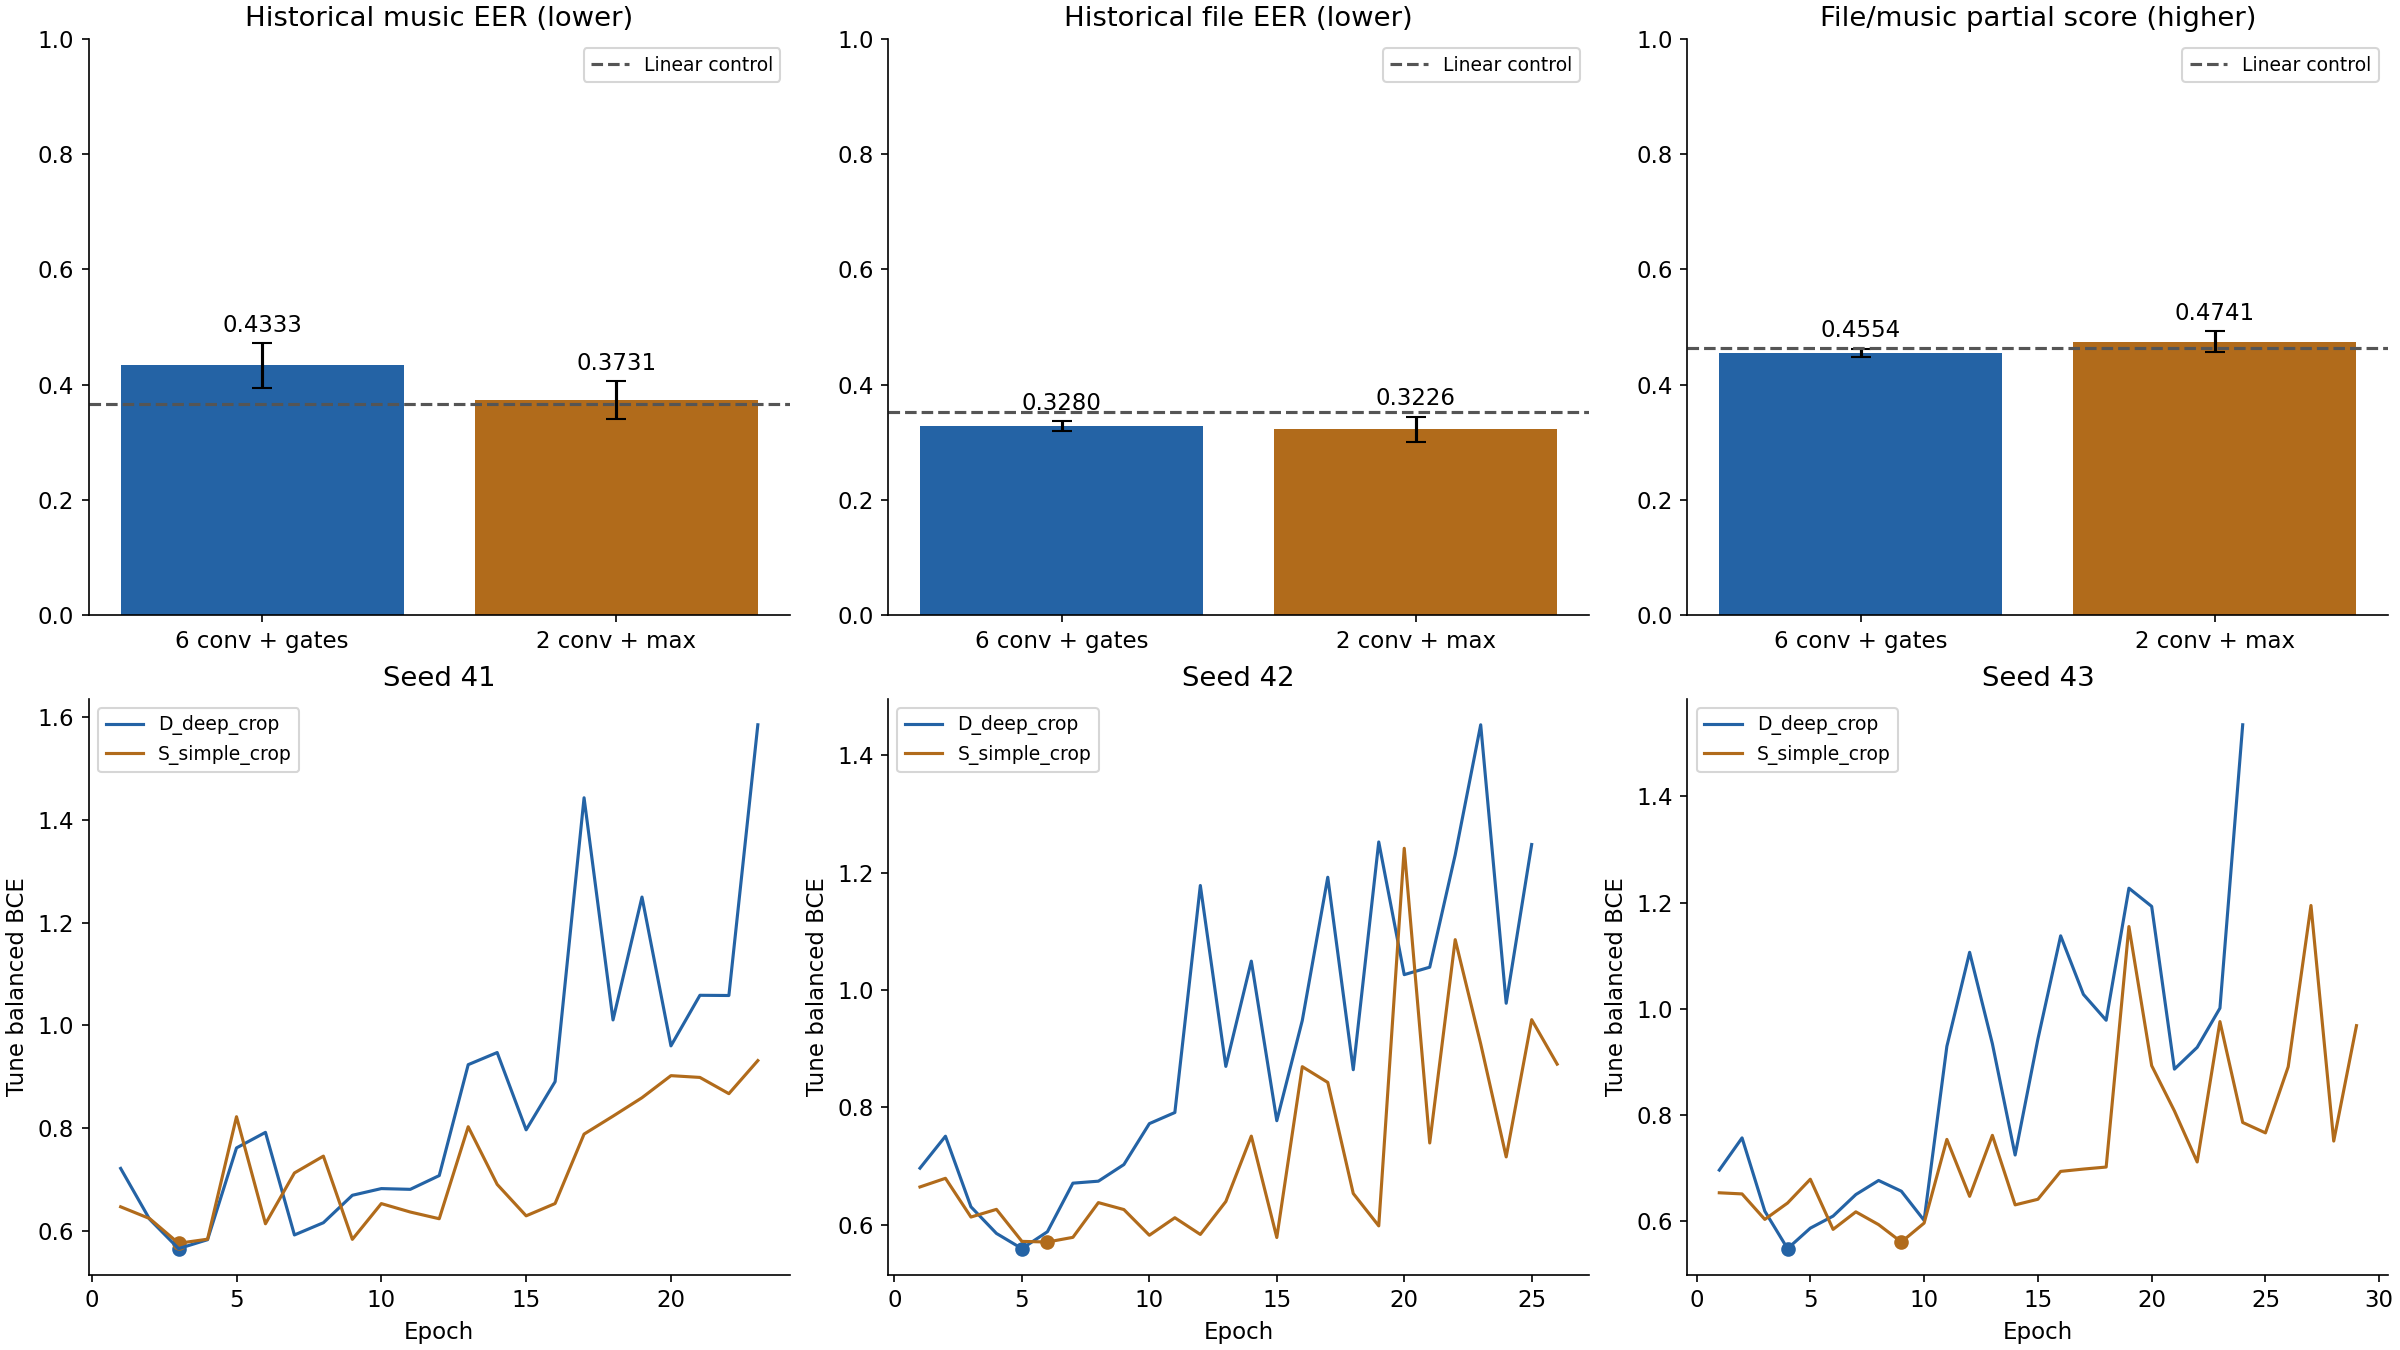

여섯 모델의 가중치·곡선·예측을 저장했습니다. 기존 평가 결과로 seed를 선택하지 않았습니다.

In [5]:
import matplotlib.pyplot as plt
from IPython.display import Image
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
colors = ['#2463a5','#b16b1b']
fig, axes = plt.subplots(2,3,figsize=(16,9),layout='constrained')
for ax,metric,title in zip(axes[0],['music_eer','file_eer','file_music_partial'],
                         ['Historical music EER (lower)','Historical file EER (lower)','File/music partial score (higher)']):
    values = [r[metric+'_mean'] for r in test_summaries]
    spread = [r[metric+'_std'] for r in test_summaries]
    ax.bar([0,1], values, yerr=spread, capsize=5, color=colors)
    ax.set(xticks=[0,1],xticklabels=['6 conv + gates','2 conv + max'],title=title,ylim=(0,1))
    for i,value in enumerate(values):
        ax.text(i,value+spread[i]+.02,f'{value:.4f}',ha='center')
    ax.axhline(reports[1][metric],color='#555555',linestyle='--',label='Linear control')
    ax.legend(fontsize=9)
for ax,seed in zip(axes[1],(41,42,43)):
    for setting,color in zip(('D_deep_crop','S_simple_crop'),colors):
        trace = json.loads((OUT/f'{setting}_seed{seed}'/'training.json').read_text())
        y = trace['validation_losses']
        ax.plot(np.arange(1,len(y)+1),y,color=color,label=setting)
        ax.scatter([trace['selected_epoch']],[trace['best_validation_loss']],color=color)
    ax.set(xlabel='Epoch',ylabel='Tune balanced BCE',title=f'Seed {seed}')
    ax.legend(fontsize=9)
fig.savefig(OUT/'comparison.png',dpi=150)
plt.close(fig)
display(Image(filename=str(OUT/'comparison.png')))
display(Markdown('여섯 모델의 가중치·곡선·예측을 저장했습니다. 기존 평가 결과로 seed를 선택하지 않았습니다.'))
